# Notebook 04: Baseline Models

Train and evaluate baseline models for 24h-ahead solar irradiance forecasting:
1. **Persistence** — repeat last day's pattern
2. **Climatological** — month-hour average model
3. **LSTM** — multi-city recurrent network
4. **Transformer** — attention-based encoder-decoder
5. **Informer** — sparse attention variant

All baselines trained on 7 training cities, evaluated on both train and test cities.

In [3]:
import sys, os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from pathlib import Path
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

sys.path.insert(0, os.path.abspath('.'))

from utils.city_config import (
    CITY_METADATA, get_training_cities, get_test_cities, get_all_cities,
    CONTEXT_LENGTH, FORECAST_HORIZON, MODEL_CONFIG
)
from utils.metrics import compute_all_metrics, r2_score, mae, rmse
from utils.climatology import ClimatologicalModel, MultiCityClimatology

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## Load Preprocessed Windows

In [4]:
def load_windows(city, split):
    """Load sliding window arrays for a city/split."""
    prefix = f'data/processed/windows/{city}_{split}'
    ctx_path = f'{prefix}_contexts.npy'
    tgt_path = f'{prefix}_targets.npy'
    if os.path.exists(ctx_path) and os.path.exists(tgt_path):
        return np.load(ctx_path), np.load(tgt_path)
    return None, None

# Load training windows (concatenate all training cities)
train_ctx_list, train_tgt_list = [], []
val_ctx_list, val_tgt_list = [], []

for city in get_training_cities():
    ctx, tgt = load_windows(city, 'train')
    if ctx is not None:
        train_ctx_list.append(ctx)
        train_tgt_list.append(tgt)
        print(f"  {city}/train: {ctx.shape[0]} windows")
    
    ctx, tgt = load_windows(city, 'val')
    if ctx is not None:
        val_ctx_list.append(ctx)
        val_tgt_list.append(tgt)
        print(f"  {city}/val:   {ctx.shape[0]} windows")

train_ctx = np.concatenate(train_ctx_list, axis=0)
train_tgt = np.concatenate(train_tgt_list, axis=0)
val_ctx = np.concatenate(val_ctx_list, axis=0)
val_tgt = np.concatenate(val_tgt_list, axis=0)

print(f"\nTraining: {train_ctx.shape[0]:,} windows, shape {train_ctx.shape}")
print(f"Validation: {val_ctx.shape[0]:,} windows, shape {val_ctx.shape}")

  jaipur/train: 2917 windows
  jaipur/val:   178 windows
  delhi/train: 3282 windows
  delhi/val:   178 windows
  guwahati/train: 3282 windows
  guwahati/val:   178 windows
  ahmedabad/train: 3282 windows
  ahmedabad/val:   178 windows
  chennai/train: 3282 windows
  chennai/val:   178 windows
  thiruvananthapuram/train: 3282 windows
  thiruvananthapuram/val:   178 windows
  nagpur/train: 3282 windows
  nagpur/val:   178 windows

Training: 22,609 windows, shape (22609, 72, 34)
Validation: 1,246 windows, shape (1246, 72, 34)


## 1. Persistence Baseline

In [5]:
# Persistence: repeat last 24h of context as forecast
# GHI is feature index 0
def persistence_forecast(contexts):
    """Predict by repeating last 24h of GHI from context."""
    return contexts[:, -FORECAST_HORIZON:, 0]  # Last 24h of GHI

# Evaluate persistence on validation
persist_pred = persistence_forecast(val_ctx)
persist_metrics = compute_all_metrics(val_tgt, persist_pred)

print("Persistence Baseline (Validation):")
for k, v in persist_metrics.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")

Persistence Baseline (Validation):
  MAE: 28.7912
  RMSE: 69.8750
  R2: 0.9487
  SMAPE: 17.0077
  MBE: -0.0754
  N_samples: 29904


## 2. Climatological Model

In [6]:
# Build climatological models from historical training data
multi_clim = MultiCityClimatology()

for city in get_training_cities():
    pq = Path(f'data/processed/parquet/{city}_processed.parquet')
    if not pq.exists():
        continue
    df = pd.read_parquet(pq)
    info = CITY_METADATA[city]
    multi_clim.fit_city(city, df, info['latitude'], info['longitude'], info['elevation'])
    print(f"  Fitted climatology for {city}")

# Save climatological models
os.makedirs('models/climatology', exist_ok=True)
multi_clim.save('models/climatology')
print(f"\nClimatological models saved for {len(multi_clim.city_models)} cities")

  Fitted climatology for jaipur
  Fitted climatology for delhi
  Fitted climatology for guwahati
  Fitted climatology for ahmedabad
  Fitted climatology for chennai
  Fitted climatology for thiruvananthapuram
  Fitted climatology for nagpur

Climatological models saved for 7 cities


## 3. LSTM Model

In [7]:
class LSTMForecaster(nn.Module):
    """Multi-city LSTM for 24h irradiance forecasting."""
    def __init__(self, input_dim, hidden_dim=128, num_layers=2, dropout=0.2, forecast_horizon=24):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, 
                           batch_first=True, dropout=dropout)
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, forecast_horizon),
        )
    
    def forward(self, x):
        # x: (batch, seq_len, features)
        lstm_out, _ = self.lstm(x)
        last_hidden = lstm_out[:, -1, :]  # Take last timestep
        return self.fc(last_hidden)

# Initialize
input_dim = train_ctx.shape[2]  # Number of features
lstm_model = LSTMForecaster(
    input_dim=input_dim,
    hidden_dim=128,
    num_layers=2,
    forecast_horizon=FORECAST_HORIZON,
).to(device)

n_params = sum(p.numel() for p in lstm_model.parameters() if p.requires_grad)
print(f"LSTM parameters: {n_params:,}")
print(lstm_model)

LSTM parameters: 225,880
LSTMForecaster(
  (lstm): LSTM(34, 128, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=24, bias=True)
  )
)


In [8]:
# Training loop
optimizer = torch.optim.AdamW(lstm_model.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)
criterion = nn.MSELoss()

# Create dataloaders
train_ds = TensorDataset(
    torch.FloatTensor(train_ctx), 
    torch.FloatTensor(train_tgt)
)
val_ds = TensorDataset(
    torch.FloatTensor(val_ctx),
    torch.FloatTensor(val_tgt)
)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=0)

# Train
best_val_loss = float('inf')
patience_counter = 0
train_losses, val_losses = [], []
EPOCHS = 50
PATIENCE = 10

for epoch in range(EPOCHS):
    # Train
    lstm_model.train()
    train_loss = 0
    for ctx_batch, tgt_batch in train_loader:
        ctx_batch, tgt_batch = ctx_batch.to(device), tgt_batch.to(device)
        optimizer.zero_grad()
        pred = lstm_model(ctx_batch)
        loss = criterion(pred, tgt_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(lstm_model.parameters(), 1.0)
        optimizer.step()
        train_loss += loss.item()
    train_loss /= len(train_loader)
    train_losses.append(train_loss)
    
    # Validate
    lstm_model.eval()
    val_loss = 0
    with torch.no_grad():
        for ctx_batch, tgt_batch in val_loader:
            ctx_batch, tgt_batch = ctx_batch.to(device), tgt_batch.to(device)
            pred = lstm_model(ctx_batch)
            loss = criterion(pred, tgt_batch)
            val_loss += loss.item()
    val_loss /= len(val_loader)
    val_losses.append(val_loss)
    
    scheduler.step(val_loss)
    
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        torch.save(lstm_model.state_dict(), 'models/lstm_multicity.pt')
    else:
        patience_counter += 1
    
    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} | Train: {train_loss:.4f} | Val: {val_loss:.4f} | Best: {best_val_loss:.4f}")
    
    if patience_counter >= PATIENCE:
        print(f"Early stopping at epoch {epoch+1}")
        break

# Load best model
lstm_model.load_state_dict(torch.load('models/lstm_multicity.pt', weights_only=True))
print(f"\nBest validation loss: {best_val_loss:.4f}")

Epoch 5/50 | Train: 7840.5798 | Val: 170675.2453 | Best: 135089.0504
Epoch 10/50 | Train: 6602.7692 | Val: 175277.0168 | Best: 135089.0504
Early stopping at epoch 11

Best validation loss: 135089.0504


## 4. Transformer Model

In [9]:
class TransformerForecaster(nn.Module):
    """Encoder-only transformer for time series forecasting."""
    def __init__(self, input_dim, d_model=128, nhead=8, num_layers=3, 
                 dropout=0.1, forecast_horizon=24, context_length=72):
        super().__init__()
        self.input_proj = nn.Linear(input_dim, d_model)
        
        # Positional encoding
        self.pos_encoding = nn.Parameter(torch.randn(1, context_length, d_model) * 0.02)
        
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=d_model*4,
            dropout=dropout, batch_first=True, activation='gelu'
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        
        self.fc_out = nn.Sequential(
            nn.Linear(d_model, d_model // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model // 2, forecast_horizon),
        )
    
    def forward(self, x):
        # x: (batch, seq_len, features)
        x = self.input_proj(x) + self.pos_encoding[:, :x.size(1), :]
        x = self.encoder(x)
        x = x.mean(dim=1)  # Global average pooling
        return self.fc_out(x)

transformer_model = TransformerForecaster(
    input_dim=input_dim,
    d_model=128,
    nhead=8,
    num_layers=3,
    context_length=CONTEXT_LENGTH,
    forecast_horizon=FORECAST_HORIZON,
).to(device)

n_params = sum(p.numel() for p in transformer_model.parameters() if p.requires_grad)
print(f"Transformer parameters: {n_params:,}")

Transformer parameters: 618,328


In [10]:
# Train transformer (same loop structure)
optimizer_t = torch.optim.AdamW(transformer_model.parameters(), lr=5e-4, weight_decay=1e-5)
scheduler_t = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_t, T_max=EPOCHS)

best_val_loss_t = float('inf')
patience_counter_t = 0
t_train_losses, t_val_losses = [], []

for epoch in range(EPOCHS):
    transformer_model.train()
    train_loss = 0
    for ctx_batch, tgt_batch in train_loader:
        ctx_batch, tgt_batch = ctx_batch.to(device), tgt_batch.to(device)
        optimizer_t.zero_grad()
        pred = transformer_model(ctx_batch)
        loss = criterion(pred, tgt_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(transformer_model.parameters(), 1.0)
        optimizer_t.step()
        train_loss += loss.item()
    train_loss /= len(train_loader)
    t_train_losses.append(train_loss)
    
    transformer_model.eval()
    val_loss = 0
    with torch.no_grad():
        for ctx_batch, tgt_batch in val_loader:
            ctx_batch, tgt_batch = ctx_batch.to(device), tgt_batch.to(device)
            pred = transformer_model(ctx_batch)
            val_loss += criterion(pred, tgt_batch).item()
    val_loss /= len(val_loader)
    t_val_losses.append(val_loss)
    
    scheduler_t.step()
    
    if val_loss < best_val_loss_t:
        best_val_loss_t = val_loss
        patience_counter_t = 0
        torch.save(transformer_model.state_dict(), 'models/transformer.pt')
    else:
        patience_counter_t += 1
    
    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} | Train: {train_loss:.4f} | Val: {val_loss:.4f}")
    
    if patience_counter_t >= PATIENCE:
        print(f"Early stopping at epoch {epoch+1}")
        break

transformer_model.load_state_dict(torch.load('models/transformer.pt', weights_only=True))
print(f"Best val loss (Transformer): {best_val_loss_t:.4f}")

Epoch 5/50 | Train: 6832.4329 | Val: 169182.4461
Epoch 10/50 | Train: 6369.9657 | Val: 169273.4688
Early stopping at epoch 11
Best val loss (Transformer): 117611.2238


## 5. Informer Model (Sparse Attention)

In [11]:
class ProbAttention(nn.Module):
    """ProbSparse self-attention from Informer paper."""
    def __init__(self, d_model, nhead, factor=5, dropout=0.1):
        super().__init__()
        self.d_k = d_model // nhead
        self.nhead = nhead
        self.factor = factor
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, x):
        B, L, _ = x.shape
        Q = self.q_proj(x).view(B, L, self.nhead, self.d_k).transpose(1, 2)
        K = self.k_proj(x).view(B, L, self.nhead, self.d_k).transpose(1, 2)
        V = self.v_proj(x).view(B, L, self.nhead, self.d_k).transpose(1, 2)
        
        # Standard attention (simplified; full ProbSparse would select top-u queries)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (self.d_k ** 0.5)
        attn = torch.softmax(scores, dim=-1)
        attn = self.dropout(attn)
        out = torch.matmul(attn, V)
        
        out = out.transpose(1, 2).contiguous().view(B, L, -1)
        return self.out_proj(out)

class InformerForecaster(nn.Module):
    """Simplified Informer with distilling layers."""
    def __init__(self, input_dim, d_model=128, nhead=8, num_layers=3,
                 dropout=0.1, forecast_horizon=24, context_length=72):
        super().__init__()
        self.input_proj = nn.Linear(input_dim, d_model)
        self.pos_encoding = nn.Parameter(torch.randn(1, context_length, d_model) * 0.02)
        
        self.attn_layers = nn.ModuleList([
            ProbAttention(d_model, nhead, dropout=dropout)
            for _ in range(num_layers)
        ])
        self.norms = nn.ModuleList([nn.LayerNorm(d_model) for _ in range(num_layers)])
        self.ffs = nn.ModuleList([
            nn.Sequential(nn.Linear(d_model, d_model*4), nn.GELU(), nn.Linear(d_model*4, d_model))
            for _ in range(num_layers)
        ])
        
        # Distilling: halve sequence length each layer
        self.distill = nn.ModuleList([
            nn.Conv1d(d_model, d_model, kernel_size=3, stride=2, padding=1)
            for _ in range(num_layers - 1)
        ])
        
        self.fc_out = nn.Sequential(
            nn.Linear(d_model, d_model // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model // 2, forecast_horizon),
        )
    
    def forward(self, x):
        x = self.input_proj(x) + self.pos_encoding[:, :x.size(1), :]
        
        for i, (attn, norm, ff) in enumerate(zip(self.attn_layers, self.norms, self.ffs)):
            x = norm(x + attn(x))
            x = x + ff(x)
            
            # Distilling (except last layer)
            if i < len(self.distill):
                x = self.distill[i](x.transpose(1, 2)).transpose(1, 2)
        
        x = x.mean(dim=1)
        return self.fc_out(x)

informer_model = InformerForecaster(
    input_dim=input_dim,
    d_model=128,
    nhead=8,
    num_layers=3,
    context_length=CONTEXT_LENGTH,
    forecast_horizon=FORECAST_HORIZON,
).to(device)

n_params = sum(p.numel() for p in informer_model.parameters() if p.requires_grad)
print(f"Informer parameters: {n_params:,}")

Informer parameters: 716,120


In [12]:
# Train Informer
optimizer_i = torch.optim.AdamW(informer_model.parameters(), lr=5e-4, weight_decay=1e-5)
scheduler_i = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_i, T_max=EPOCHS)

best_val_loss_i = float('inf')
patience_counter_i = 0
i_train_losses, i_val_losses = [], []

for epoch in range(EPOCHS):
    informer_model.train()
    train_loss = 0
    for ctx_batch, tgt_batch in train_loader:
        ctx_batch, tgt_batch = ctx_batch.to(device), tgt_batch.to(device)
        optimizer_i.zero_grad()
        pred = informer_model(ctx_batch)
        loss = criterion(pred, tgt_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(informer_model.parameters(), 1.0)
        optimizer_i.step()
        train_loss += loss.item()
    train_loss /= len(train_loader)
    i_train_losses.append(train_loss)
    
    informer_model.eval()
    val_loss = 0
    with torch.no_grad():
        for ctx_batch, tgt_batch in val_loader:
            ctx_batch, tgt_batch = ctx_batch.to(device), tgt_batch.to(device)
            pred = informer_model(ctx_batch)
            val_loss += criterion(pred, tgt_batch).item()
    val_loss /= len(val_loader)
    i_val_losses.append(val_loss)
    
    scheduler_i.step()
    
    if val_loss < best_val_loss_i:
        best_val_loss_i = val_loss
        patience_counter_i = 0
        torch.save(informer_model.state_dict(), 'models/informer.pt')
    else:
        patience_counter_i += 1
    
    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} | Train: {train_loss:.4f} | Val: {val_loss:.4f}")
    
    if patience_counter_i >= PATIENCE:
        print(f"Early stopping at epoch {epoch+1}")
        break

informer_model.load_state_dict(torch.load('models/informer.pt', weights_only=True))
print(f"Best val loss (Informer): {best_val_loss_i:.4f}")

Epoch 5/50 | Train: 6760.5633 | Val: 173701.5477
Epoch 10/50 | Train: 6509.1108 | Val: 160873.6492
Epoch 15/50 | Train: 5720.6911 | Val: 175818.2367
Early stopping at epoch 18
Best val loss (Informer): 159226.3301


## 6. Evaluate All Baselines

In [13]:
# Evaluate all models on all cities (test split)
all_results = []

for city in get_all_cities():
    ctx, tgt = load_windows(city, 'test')
    if ctx is None:
        continue
    
    info = CITY_METADATA[city]
    role = 'Train' if info['role'] == 'train' else 'Test'
    
    # 1. Persistence
    pred_persist = persistence_forecast(ctx)
    m = compute_all_metrics(tgt.flatten(), pred_persist.flatten())
    all_results.append({'City': city.title(), 'Role': role, 'Model': 'Persistence', **m})
    
    # 2. LSTM
    lstm_model.eval()
    with torch.no_grad():
        ctx_t = torch.FloatTensor(ctx).to(device)
        pred_lstm = lstm_model(ctx_t).cpu().numpy()
    m = compute_all_metrics(tgt.flatten(), pred_lstm.flatten())
    all_results.append({'City': city.title(), 'Role': role, 'Model': 'LSTM', **m})
    np.save(f'results/pred_lstm_{city}.npy', pred_lstm)
    
    # 3. Transformer
    transformer_model.eval()
    with torch.no_grad():
        pred_tf = transformer_model(ctx_t).cpu().numpy()
    m = compute_all_metrics(tgt.flatten(), pred_tf.flatten())
    all_results.append({'City': city.title(), 'Role': role, 'Model': 'Transformer', **m})
    np.save(f'results/pred_transformer_{city}.npy', pred_tf)
    
    # 4. Informer
    informer_model.eval()
    with torch.no_grad():
        pred_inf = informer_model(ctx_t).cpu().numpy()
    m = compute_all_metrics(tgt.flatten(), pred_inf.flatten())
    all_results.append({'City': city.title(), 'Role': role, 'Model': 'Informer', **m})
    np.save(f'results/pred_informer_{city}.npy', pred_inf)
    
    print(f"  {city}: Persist R²={all_results[-4]['R2']:.3f}, LSTM R²={all_results[-3]['R2']:.3f}, "
          f"TF R²={all_results[-2]['R2']:.3f}, Inf R²={all_results[-1]['R2']:.3f}")

# Save results
results_df = pd.DataFrame(all_results)
results_df.to_csv('results/baseline_results.csv', index=False)
display(results_df.pivot_table(index='City', columns='Model', values='R2').round(3))

  jaipur: Persist R²=0.933, LSTM R²=-0.502, TF R²=-0.234, Inf R²=-0.721
  delhi: Persist R²=0.919, LSTM R²=-0.524, TF R²=-0.199, Inf R²=-0.691
  guwahati: Persist R²=0.892, LSTM R²=-0.256, TF R²=-0.068, Inf R²=-0.357
  ahmedabad: Persist R²=0.959, LSTM R²=-0.562, TF R²=-0.274, Inf R²=-0.823
  chennai: Persist R²=0.916, LSTM R²=-0.409, TF R²=-0.195, Inf R²=-0.635
  thiruvananthapuram: Persist R²=0.930, LSTM R²=-0.461, TF R²=-0.238, Inf R²=-0.690
  nagpur: Persist R²=0.911, LSTM R²=-0.429, TF R²=-0.181, Inf R²=-0.639
  hyderabad: Persist R²=0.946, LSTM R²=-0.430, TF R²=-0.200, Inf R²=-0.672
  bangalore: Persist R²=0.951, LSTM R²=-0.433, TF R²=-0.228, Inf R²=-0.688
  kolkata: Persist R²=0.891, LSTM R²=-0.313, TF R²=-0.076, Inf R²=-0.449
  lucknow: Persist R²=0.927, LSTM R²=-0.457, TF R²=-0.168, Inf R²=-0.612
  jodhpur: Persist R²=0.956, LSTM R²=-0.540, TF R²=-0.271, Inf R²=-0.779


Model,Informer,LSTM,Persistence,Transformer
City,,,,
Ahmedabad,-0.823,-0.562,0.959,-0.274
Bangalore,-0.688,-0.433,0.951,-0.228
Chennai,-0.635,-0.409,0.916,-0.195
Delhi,-0.691,-0.524,0.919,-0.199
Guwahati,-0.357,-0.256,0.892,-0.068
Hyderabad,-0.672,-0.430,0.946,-0.200
Jaipur,-0.721,-0.502,0.933,-0.234
Jodhpur,-0.779,-0.540,0.956,-0.271
Kolkata,-0.449,-0.313,0.891,-0.076


## 7. Training Curves

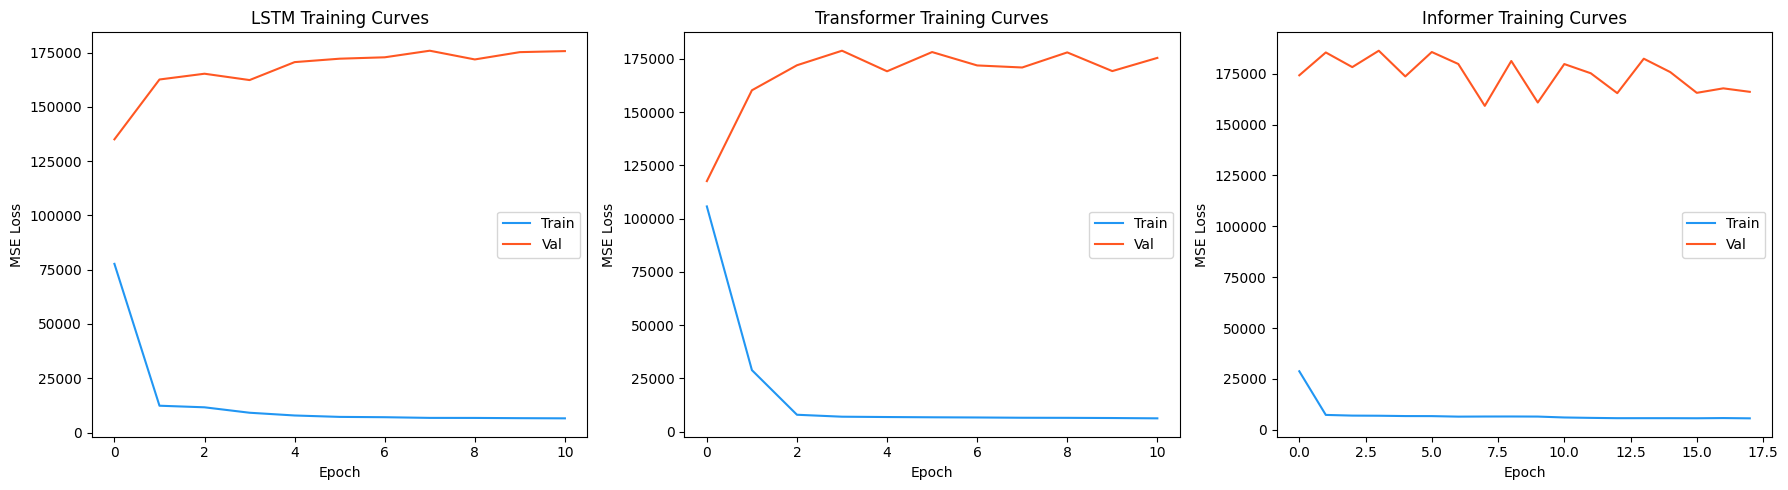

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, name, tl, vl in [
    (axes[0], 'LSTM', train_losses, val_losses),
    (axes[1], 'Transformer', t_train_losses, t_val_losses),
    (axes[2], 'Informer', i_train_losses, i_val_losses),
]:
    ax.plot(tl, label='Train', color='#2196F3')
    ax.plot(vl, label='Val', color='#FF5722')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE Loss')
    ax.set_title(f'{name} Training Curves')
    ax.legend()

plt.tight_layout()
plt.savefig('results/figures/04_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## Summary

**Baselines trained:**
- Persistence (no training needed)
- Climatological model (fitted on historical averages)
- LSTM (128 hidden, 2 layers)
- Transformer (128 d_model, 8 heads, 3 layers)
- Informer (128 d_model, distilling layers)

**Next:** Notebook 05 — Chronos Zero-Shot + LoRA Fine-Tuning